# D5 – Mini-projet : une série temporelle

**Python numérique – devoir n° 5 – à rendre pour le dimanche 18 octobre 2026, 23 h 59** (la séance 6 est le mardi 20)

Bienvenue dans votre cinquième devoir ! Nous allons y mettre en œuvre les notions vues en séance 5 : `to_datetime`, `DatetimeIndex`, la sélection par dates, `resample`, `rolling`, `df.plot` et les figures à plusieurs sous-graphiques avec `matplotlib`. C'est aussi un mini-projet : la dernière partie est ouverte, et c'est vous qui choisissez la question à laquelle répondre.

Durée indicative : 1 h 30.

````{admonition} Consignes de rendu
:class: important

* Ce notebook reste dans le dossier `D5/` de votre dépôt `pe-homework` (celui que le zip du sujet a créé en se dézippant), avec ses figures à côté, puis il doit être **commité et poussé** (`git add`, `git commit`, `git push`) avant la deadline. Attention, c'est la **date du commit** qui fait foi, pas celle du push ; le nom du fichier, lui, n'a pas d'importance (`sujet.ipynb` convient très bien). Le dossier `data/` livré avec le sujet reste lui aussi dans `D5/` : `git add D5` embarque tout le dossier, et c'est très bien ainsi (il ne pèse que quelques kilo-octets).
* Juste avant de rendre, **pensez à ré-exécuter toutes les cellules** via *Kernel → Restart Kernel and Run All Cells* : toutes doivent s'exécuter dans l'ordre et sans erreur. En effet, un notebook qui plante à mi-chemin sera corrigé jusqu'à l'erreur…
* Le notebook lit les données dans `data/comptage-velos.csv` (chemin relatif) ; la figure `serie.png` est quant à elle écrite dans le dossier du notebook.
* Les cellules `# votre code` sont à compléter ; vous pouvez ajouter autant de cellules que vous le souhaitez. Les cellules de test (`assert`) sont là pour vous aider : si elles passent sans erreur, c'est bon signe. Ne les modifiez pas !
* Répondez aux questions "en français" dans une cellule *Markdown*, en deux ou trois phrases. Dans ce devoir, la rédaction compte autant que le code.
````

````{admonition} Ce qui est autorisé
:class: note

* La documentation de `pandas` / `matplotlib`, les notebooks du cours, vos notes.
* Les assistants IA sont tolérés, avec la règle habituelle : **vous devez être capable d'expliquer chaque ligne que vous rendez**, et je pourrai vous demander de le faire à l'oral en séance. Le devoir est individuel.
* En revanche, pas de boucle `for` sur les lignes de la série : tout se fait avec les opérations `pandas`.
````

````{admonition} Les données
:class: warning

`data/comptage-velos.csv` contient le nombre de vélos comptés chaque jour par un compteur automatique installé sur une piste cyclable parisienne, du 1er janvier 2023 au 31 décembre 2024 : une colonne `date` (texte `AAAA-MM-JJ`) et une colonne `comptage`, séparées par `;`.

Attention, **ces données sont simulées** : je les ai produites avec le script `data/generate.py`, en fixant la graine afin que tout le monde travaille sur les mêmes valeurs. Vous pouvez le lire, mais seulement *après* avoir fait le devoir ! Elles ont cependant l'allure de vraies données de comptage, défauts compris : le fichier n'est pas trié, certaines lignes sont en double, certains jours n'ont pas de mesure, et le capteur a eu au moins deux ratés. Ainsi, comme dans la vraie vie, vous allez d'abord nettoyer, puis analyser.
````

## Barème

| Exercice | Contenu | Points |
|---|---|---|
| 1 | Chargement, index temporel, diagnostic et nettoyage | 6 |
| 2 | Rééchantillonnage (`resample`) et lissage (`rolling`) | 4 |
| 3 | Profils hebdomadaire et mensuel, 2023 vs 2024 | 4 |
| 4 | Figure à deux sous-graphiques `serie.png` | 3 |
| 5 | Question ouverte : une question, une figure, trois lignes de conclusion | 3 |
| **Total** | | **20** |
| Bonus | Jour le plus creux, croissance annuelle | +2 |

*Inspiré des exercices de <https://numerique-exos.info-mines.paris>.*

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Exercice 1 – Charger, indexer, nettoyer (6 pts)

**1.a** Lisez le fichier dans une `DataFrame` `df` et affichez `df.info()`. Quel est le type de la colonne `date` ? Pourquoi n'est-ce pas satisfaisant ? Le fichier est-il trié par date ?

In [2]:
df=pd.read_csv("data/comptage-velos.csv", sep=";")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      734 non-null    str    
 1   comptage  726 non-null    float64
dtypes: float64(1), str(1)
memory usage: 11.6 KB


In [3]:
df

,date,comptage
0,2023-01-01,304.0
1,2023-01-02,1658.0
2,2023-01-03,1450.0
3,2023-01-04,1902.0
4,2023-01-05,1715.0
...,...,...
729,2024-12-30,1900.0
730,2024-12-31,2126.0
731,2023-12-21,1960.0
732,2023-05-25,3101.0


**La colonne des dates est stockée en type str, le tri sur la colonne va donc utiliser l'ordre lexicographique et non l'ordre logique chronologique, ce qui est gênant.** 

**Le fichier n'est pas trié par date --> on remarque des date en 2023, puis en 2024, puis encore en 2023 dans le fichier brut**

In [4]:
assert df.shape == (734, 2)
assert list(df.columns) == ["date", "comptage"]
print("ok")

ok


**1.b** Construisez maintenant la `Series` `brut` : les comptages indexés par la date, avec un vrai `DatetimeIndex`, triée par date et en flottants.

In [5]:
df["date"]=pd.to_datetime(df["date"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      734 non-null    datetime64[us]
 1   comptage  726 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 11.6 KB


In [6]:
brut=df["comptage"]
brut.index=df["date"].sort_values()
brut

date
2023-01-01     304.0
2023-01-02    1658.0
2023-01-03    1450.0
2023-01-04    1902.0
2023-01-05    1715.0
               ...  
2024-12-27    1900.0
2024-12-28    2126.0
2024-12-29    1960.0
2024-12-30    3101.0
2024-12-31    2622.0
Name: comptage, Length: 734, dtype: float64

In [7]:
assert isinstance(brut, pd.Series)
assert isinstance(brut.index, pd.DatetimeIndex)
assert brut.index.is_monotonic_increasing
assert len(brut) == 734
assert brut.index[0] == pd.Timestamp("2023-01-01") and brut.index[-1] == pd.Timestamp("2024-12-31")
print("ok")

ok


````{admonition} Pas encore vu en cours : duplicated()
:class: note

`serie.duplicated()` — ou `index.duplicated()` — renvoie un tableau de booléens de même longueur, avec `True` sur les valeurs *déjà rencontrées plus haut* : la première occurrence vaut `False`, les suivantes `True`. Ainsi, sur `[3, 1, 3, 3]`, on obtient `[False, False, True, True]`. Combiné à `~`, il permet donc de ne garder que la première occurrence de chaque valeur.
````

**1.c** Place au diagnostic. Répondez d'abord par du code, puis résumez vos observations dans une cellule Markdown :

* combien de dates apparaissent en double ? lesquelles ?
* combien de valeurs manquantes ? quels jours ?
* observez `brut.describe()` : le minimum et le maximum vous semblent-ils plausibles pour un compteur vélo ? Affichez les jours dont le comptage est nul, et ceux dont le comptage dépasse 3 fois la médiane.

In [8]:
double=len(df.loc[df["date"].duplicated(),"date"].unique())
double

3

In [9]:
df.loc[df["date"].duplicated(),"date"].unique()

<DatetimeArray>
['2023-12-21 00:00:00', '2023-05-25 00:00:00', '2024-02-27 00:00:00']
Length: 3, dtype: datetime64[us]

In [10]:
manquantes=brut.isna().sum()
manquantes

np.int64(8)

In [11]:
valeurs_manquantes=df["comptage"].isna()
df[valeurs_manquantes]["date"]

53    2023-02-23
135   2024-11-22
175   2023-06-25
334   2023-12-01
373   2024-01-09
403   2024-02-08
437   2024-03-13
686   2024-11-17
Name: date, dtype: datetime64[us]

In [12]:
brut.describe()

count      726.000000
mean      2454.612948
std       1646.281515
min          0.000000
25%       1770.250000
50%       2301.000000
75%       3090.000000
max      39660.000000
Name: comptage, dtype: float64

In [13]:
df.loc[df["comptage"]==0]["date"]

543   2024-06-27
Name: date, dtype: datetime64[us]

In [14]:
df.loc[df["comptage"]>=3*brut.median()]["date"]

550   2024-07-04
Name: date, dtype: datetime64[us]

In [15]:
df.iloc[550]

date        2024-07-04 00:00:00
comptage                39660.0
Name: 550, dtype: object

Cohérent avec la valeur maximale, et c'est la seule pour laquelle on dépasse 3x la valeur médiane

**3 dates apparaissent en double : 2023-12-21, 2023-05-25, 2024-02-27**

**8 valeurs manquantes : 2023-02-23, 2024-11-22, 2023-06-25, 2023-12-01, 2024-01-09, 2024-02-08, 2024-03-13**

**Le minimum est 0, possible si une station est vide, le maximum est aberrant : 39660 ça fait une sacrée station vélib**

**Comptage nul : 2024-06-27**

**Comptage supérieur à 3 fois la médiance : 2024-07-04**

In [16]:
assert brut.index.duplicated().sum() == 3
assert brut.isna().sum() == 8
assert (brut == 0).sum() == 1
assert (brut > 3 * brut.median()).sum() == 1
print("ok")

ok


````{admonition} Pas encore vu en cours : interpolate()
:class: note

`serie.interpolate()` remplace chaque `NaN` par une valeur déduite de ses voisins non manquants, par interpolation linéaire par défaut : sur `[10, NaN, NaN, 40]`, on obtient `[10, 20, 30, 40]`. C'est l'alternative à `fillna` quand les données ont un ordre naturel, comme ici le temps.
````

**1.d** Passons au nettoyage. Construisez la série propre `velos`, en trois temps :

1. supprimez les doublons d'index en ne gardant que la première occurrence (`duplicated()`) ;
2. remplacez les deux valeurs aberrantes (comptage nul ou supérieur à 3 fois la médiane) par `NaN` ;
3. remplissez tous les `NaN` (les 8 jours vides + les 2 aberrants) par interpolation linéaire.

Vérifiez enfin que `velos` a exactement une valeur par jour du 1er janvier 2023 au 31 décembre 2024 (soit 731 jours), et plus aucun `NaN`.

In [17]:
velos=df.loc[~df["date"].duplicated(),"comptage"]
sum(~df["date"].duplicated())

731

In [18]:
df=df.sort_values("date")
velos=df.loc[~df["date"].duplicated(),"comptage"]
velos.index=df.loc[~df["date"].duplicated(),"date"]
velos[(velos>=3*velos.median())|(velos==0)|velos.isna()]=np.nan
velos=velos.interpolate()

In [19]:
velos

date
2023-01-01     304.0
2023-01-02    1658.0
2023-01-03    1450.0
2023-01-04    1902.0
2023-01-05    1715.0
               ...  
2024-12-27    1906.0
2024-12-28    1186.0
2024-12-29    1040.0
2024-12-30    1900.0
2024-12-31    2126.0
Name: comptage, Length: 731, dtype: float64

In [20]:
assert len(velos) == 731
assert velos.isna().sum() == 0
assert not velos.index.duplicated().any()
assert (velos.index == pd.date_range("2023-01-01", "2024-12-31", freq="D")).all()
assert velos.min() > 100 and velos.max() < 6000
assert abs(velos.loc["2024-07-04"] - (velos.loc["2024-07-03"] + velos.loc["2024-07-05"]) / 2) < 1
print("ok")

ok


## Exercice 2 – Rééchantillonner et lisser (4 pts)

**2.a** Calculez :

* `hebdo` : la moyenne par semaine ;
* `mensuel` : la moyenne par mois (l'alias de fréquence des mois est `"ME"`, *month end*, depuis pandas 2.2 ; `"M"` si votre pandas est plus ancien) ;
* `annuel` : le **total** par année.

Combien de lignes ont `hebdo` et `mensuel` ? Pourquoi `hebdo` n'a-t-il pas exactement 731 / 7 lignes ?

In [21]:
hebdo=velos.resample("W").mean()
mensuel=velos.resample("ME").mean()
annuel=velos.resample("YE").sum()

In [22]:
assert len(hebdo) == 106 and len(mensuel) == 24 and len(annuel) == 2
assert abs(mensuel.sum() * 30.4 - velos.sum()) / velos.sum() < 0.05
assert annuel.iloc[1] > annuel.iloc[0]
print("ok")

ok


**2.b** Calculez `lisse`, la moyenne glissante **centrée** sur 7 jours. Combien de `NaN` contient-elle, et où ? Pourquoi 7 jours est-il un bon choix de fenêtre pour cette série ? Enfin, tracez `velos` (trait fin, transparent) et `lisse` sur le même graphique, avec la méthode `.plot()` des `Series`.

6


Text(0, 0.5, 'Nombre de vélos')

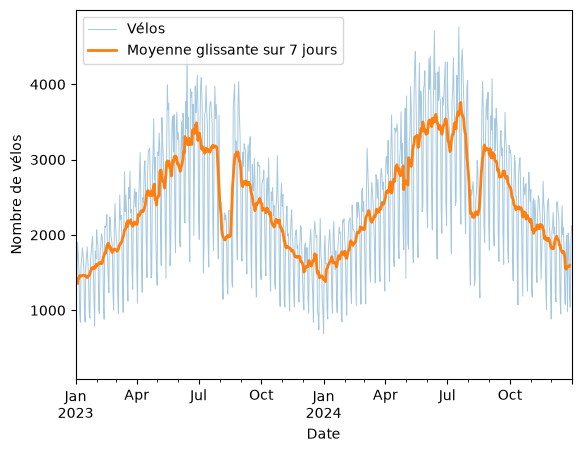

In [23]:
lisse=velos.rolling(7, center=True).mean()
print(sum(lisse.isna()))
velos.plot(style="-", linewidth=0.7, alpha=0.4, label="Vélos")
lisse.plot(linewidth=2, label="Moyenne glissante sur 7 jours")
plt.legend()
plt.xlabel("Date")
plt.ylabel("Nombre de vélos")

**Il y a 6 valeurs NaN, et la moyenne sur 7 jours est intéressante car elle est suffisamment faible pour tenir compte des variations d'usage, mais assez grande pour effacer les oscillations de plus grande fréquence, d'autant plus qu'il paraît raisonnable de considérer que l'usage des vélos est 7jours-périodique**

In [24]:
assert len(lisse) == 731
assert lisse.isna().sum() == 6
assert abs(lisse.loc["2023-06-15"] - velos.loc["2023-06-12":"2023-06-18"].mean()) < 1e-9
print("ok")

ok


## Exercice 3 – Profils (4 pts)

**3.a** Commençons par le profil hebdomadaire : calculez `profil_semaine`, la moyenne des comptages pour chaque jour de la semaine, avec 0 = lundi … 6 = dimanche. Remplacez ensuite l'index `0..6` par les noms des jours (`"lun"`, `"mar"`, … `"dim"`). De combien (en %) le dimanche est-il plus bas que la moyenne des jours de semaine (lundi à vendredi) ?

In [25]:
profil_semaine=velos.groupby(velos.index.dayofweek).mean()
jours=["lun","mar","mer","jeu","ven","sam","dim"]
profil_semaine.index=jours
profil_semaine

lun    2694.095238
mar    2868.504762
mer    2877.658654
jeu    2782.269231
ven    2595.394231
sam    1639.942308
dim    1386.380952
Name: comptage, dtype: float64

In [26]:
assert profil_semaine.shape == (7,)
assert list(profil_semaine.index) == ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
assert profil_semaine["sam"] < 0.75 * profil_semaine["lun"]
assert profil_semaine["dim"] < profil_semaine["sam"]
print("ok")

ok


````{admonition} Pas encore vu en cours : idxmax et idxmin
:class: note

`serie.idxmax()` renvoie l'**étiquette** de la plus grande valeur (ici un numéro de mois), alors que `serie.max()` renvoie la valeur elle-même ; `idxmin` fait de même pour la plus petite. Sur une série indexée par des dates, on récupère donc directement le `Timestamp` du maximum.
````

**3.b** Intéressons-nous maintenant à la saisonnalité : calculez `profil_mois`, la moyenne pour chaque mois de l'année (1 à 12), les deux années confondues. Quel est le mois le plus chargé ? Et que se passe-t-il en août ?

In [27]:
profil_mois=velos.groupby(velos.index.month).mean()
profil_mois

date
1     1547.806452
2     1845.000000
3     2144.024194
4     2585.300000
5     3013.000000
6     3313.183333
7     3285.483871
8     2535.774194
9     2693.766667
10    2309.419355
11    1924.308333
12    1657.911290
Name: comptage, dtype: float64

In [28]:
profil_mois.idxmax()

np.int32(6)

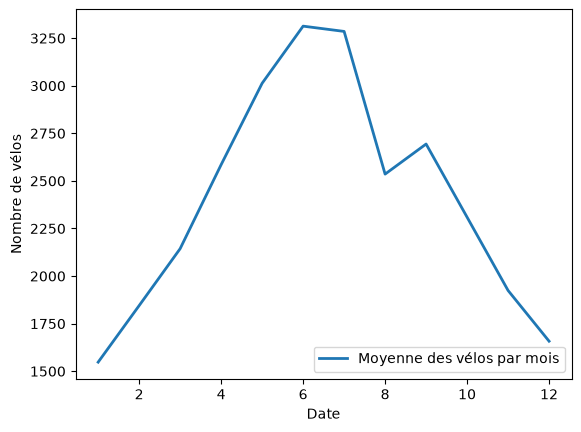

In [29]:
profil_mois.plot(linewidth=2, label="Moyenne des vélos par mois");
plt.legend()
plt.xlabel("Date")
plt.ylabel("Nombre de vélos");

**Le mois le plus chargé est juin, et en août arrive une forte décroissance du nombre de passage des vélos, d'environ 40%**

In [30]:
assert profil_mois.shape == (12,) and list(profil_mois.index) == list(range(1, 13))
assert profil_mois.idxmax() in (6, 7)
assert profil_mois[8] < profil_mois[7] and profil_mois[8] < profil_mois[9]
assert profil_mois.idxmin() in (1, 12)
print("ok")

ok


**3.c** Opposons enfin 2023 à 2024 : avec la sélection par chaîne de date, calculez la moyenne journalière de chaque année, puis la croissance en % de 2023 à 2024 (variable `croissance`). Posez-vous ensuite la même question mois par mois : construisez la table `par_mois` de forme `(12, 2)` (lignes = mois, colonnes = années) — `unstack` peut aider — et repérez le mois où la progression a été la plus forte.

In [31]:
profil_année=velos.groupby(velos.index.year).mean()
profil_année

date
2023    2285.983562
2024    2525.591530
Name: comptage, dtype: float64

In [32]:
croissance=(profil_année.loc[2024]-profil_année.loc[2023])/profil_année.loc[2023]*100
croissance

np.float64(10.481613797717293)

In [33]:
par_mois=velos.groupby([velos.index.month,velos.index.year]).mean().unstack()
par_mois

date,2023,2024
date,,
1,1451.612903,1644.000000
2,1755.160714,1931.741379
3,2053.516129,2234.532258
4,2393.466667,2777.133333
5,2849.903226,3176.096774
6,3223.133333,3403.233333
7,3091.870968,3479.096774
8,2454.193548,2617.354839
9,2537.033333,2850.500000


In [34]:
assert 7 < croissance < 14
assert par_mois.shape == (12, 2)
assert list(par_mois.columns) == [2023, 2024]
assert (par_mois[2024] > par_mois[2023]).sum() >= 10
print("ok")

ok


In [35]:
par_mois["croissance"]=(par_mois.loc[:,2024]-par_mois.loc[:,2023])/par_mois.loc[:,2023]*100
par_mois

date,2023,2024,croissance
date,,,
1,1451.612903,1644.000000,13.253333
2,1755.160714,1931.741379,10.060655
3,2053.516129,2234.532258,8.814936
4,2393.466667,2777.133333,16.029748
5,2849.903226,3176.096774,11.445776
6,3223.133333,3403.233333,5.587730
7,3091.870968,3479.096774,12.523996
8,2454.193548,2617.354839,6.648265
9,2537.033333,2850.500000,12.355638


In [36]:
print(par_mois.loc[:,"croissance"].idxmax())

4


**Le mois de plus forte croissance d'une année à l'autre est avril**

## Exercice 4 – Figure à deux sous-graphiques (3 pts)

Construisez une figure `fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))` :

* en haut : la série journalière `velos` (trait fin, transparent) et la série lissée `lisse` (trait plus épais), avec une légende, un titre et un nom d'axe des ordonnées ;
* en bas : le profil hebdomadaire `profil_semaine` en barres, avec un titre et un nom d'axe des ordonnées.

Terminez par `fig.tight_layout()` et enregistrez dans `serie.png` (`fig.savefig`).

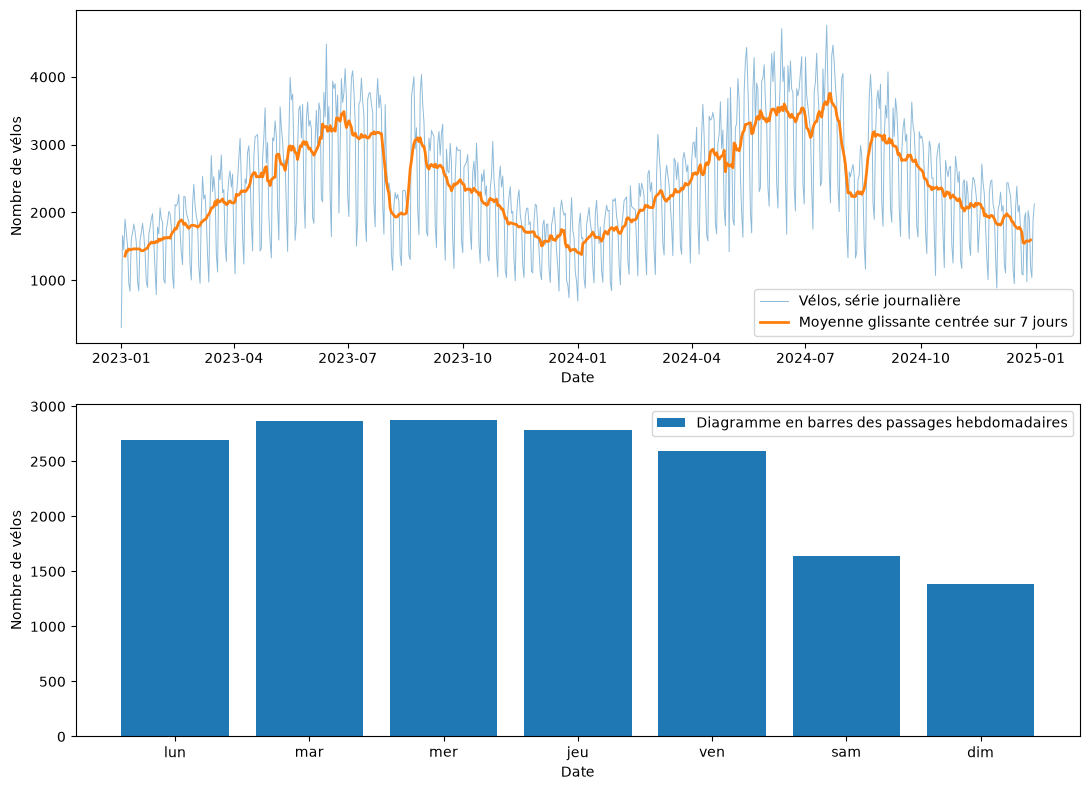

In [37]:
fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))
ax_haut.plot(velos, linewidth=0.7, alpha=0.5, label="Vélos, série journalière")
ax_haut.plot(lisse, linewidth=2, alpha=1, label="Moyenne glissante centrée sur 7 jours")
ax_haut.legend()
ax_haut.set_xlabel("Date")
ax_haut.set_ylabel("Nombre de vélos")
ax_bas.bar(profil_semaine.index, profil_semaine.values, label="Diagramme en barres des passages hebdomadaires")
ax_bas.legend()
ax_bas.set_xlabel("Date")
ax_bas.set_ylabel("Nombre de vélos")
fig.tight_layout()
fig.savefig("serie.png")

In [38]:
assert os.path.exists("serie.png")
print("ok")

ok


## Exercice 5 – Question ouverte (3 pts)

C'est ici que vous prenez la main ! Choisissez **une** question sur cette série, puis répondez-y avec une figure (au moins une courbe ou un diagramme, légendée et titrée) et trois lignes de conclusion en Markdown. Voici quelques idées, mais une question à vous est la bienvenue :

* le creux d'août a-t-il la même ampleur en 2023 et en 2024 ?
* l'écart week-end / semaine est-il le même en été et en hiver ?
* quelle semaine de l'année est la plus chargée ? la plus creuse ? est-ce la même les deux années ?
* la croissance entre 2023 et 2024 est-elle uniforme sur l'année, ou concentrée sur certains mois ?
* que se passe-t-il autour des jours fériés que vous connaissez ?

Côté barème, je compte un point pour la pertinence de la méthode, un point pour une figure lisible et correcte, et un point pour une conclusion chiffrée et honnête.

In [39]:
profil_hebdo=velos.groupby([pd.Grouper(freq="W"),velos.index.year]).mean().unstack()
profil_hebdo

date,2023,2024
date,,
2023-01-01,304.000000,NaN
2023-01-08,1433.714286,NaN
2023-01-15,1464.000000,NaN
2023-01-22,1442.714286,NaN
2023-01-29,1549.285714,NaN
...,...,...
2024-12-08,NaN,1846.857143
2024-12-15,NaN,1919.428571
2024-12-22,NaN,1781.285714


In [40]:
print(profil_hebdo.idxmax(), profil_hebdo.max())
print(profil_hebdo.idxmin(), profil_hebdo.min())

date
2023   2023-06-25
2024   2024-07-21
dtype: datetime64[us] date
2023    3390.714286
2024    3589.857143
dtype: float64
date
2023   2023-01-01
2024   2024-01-07
dtype: datetime64[us] date
2023     304.000000
2024    1379.714286
dtype: float64


Text(0, 0.5, 'Nombre de vélos')

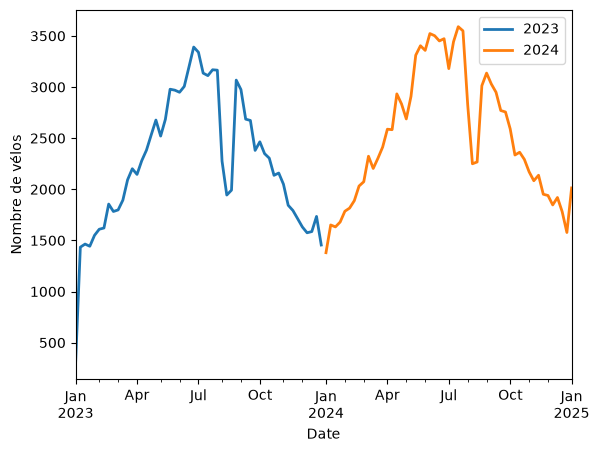

In [41]:
profil_hebdo.plot(linewidth=2, label="Moyenne de comptage pour chaque semaine sur les deux années")
plt.legend()
plt.xlabel("Date")
plt.ylabel("Nombre de vélos")

**La semaine la plus chargée est celle du 25 juin en 2023 avec 3390 comptages en moyenne, et celle du 21 juillet en 2024 avec 3589 comptages en moyenne, soit 1 mois de décalage environ**

**La semaine la plus creuse est celle du 1er janvier en 2023 avec 304 comptages en moyenne, et celle du 7 janvier en 2024 avec 1379 comptages en moyenne, soit 1 semaine de décalage**

**Remarquons que la semaine à 304 comptages semble légèrement aberrante, mais on peut supposer la présence de travaux sur la piste cyclable cette semaine......**

## Bonus (+2)

**Bo.1** Quel est le jour le plus creux de toute la série ? Et le plus chargé ? Pour chacun, donnez le jour de la semaine (`.day_name()`) et proposez une explication.

````{admonition} Pas encore vu en cours : pct_change
:class: note

`serie.pct_change()` renvoie la variation *relative* d'une valeur à la suivante : sur `[100, 110, 99]`, elle donne `[NaN, 0.10, -0.10]`. La première case vaut `NaN` faute de valeur précédente, et le résultat est une proportion, à multiplier par 100 pour l'exprimer en pourcentage.
````

**Bo.2** Calculez la croissance annuelle en % à partir des totaux annuels `annuel`. Pourquoi ce chiffre est-il légèrement différent de `croissance` (exercice 3.c) ?

In [42]:
print(velos.idxmin(),velos.idxmin().day_name())

2023-01-01 00:00:00 Sunday


Le jour le plus creux est le dimanche 1er janvier 2023 : jour de l'an donc peu de déplacements

In [43]:
print(velos.idxmax(),velos.idxmax().day_name())

2024-07-18 00:00:00 Thursday


Le jour le plus creux est le jeudi 18 juillet 2024 : vacances scolaires, beau temps, juste avant les jeux olympiques

In [44]:
annuel

date
2023-12-31    834384.0
2024-12-31    924366.5
Freq: YE-DEC, Name: comptage, dtype: float64

In [45]:
annuel.pct_change()*100

date
2023-12-31          NaN
2024-12-31    10.784303
Freq: YE-DEC, Name: comptage, dtype: float64

In [46]:
croissance

np.float64(10.481613797717293)

**Les valeurs sont proches mais distinctes, on peut l'expliquer par le fait que croissance calcule le taux de variation entre les moyennes par année, et que pct_change() à partir de annuel calcule le taux de variation entre le total de vélos utilisés entre 2023 et 2024**

Bon courage à tous ! Pour toute question sur le sujet, vous pouvez me contacter par email : [raphael@imagine-app.fr](mailto:raphael@imagine-app.fr).

Au plaisir de vous lire,

votre responsable de cours, Raphael Prasquier
(sujet conçu par Aurélien Noce)